# Costco Analytics — Session 1: Meet the numbers

**Goal:** Use audited, real-world company data to explore revenue growth, margins, and inventory efficiency **before** choosing a fancy model.

**Source:** [Costco fiscal 2026 Form 10-K](https://www.sec.gov/Archives/edgar/data/909832/000090983226000093/cost-20260830.htm), consolidated income statements (fiscal 2024–26) and balance sheets (fiscal 2025–26). Figures are in **USD millions**, not dollars.

We deliberately start with an offline CSV to make the first calculations reproducible. Later cells can download Costco's large Company Facts JSON directly from SEC EDGAR. Nothing in the CSV is fabricated. Blank values mean **not included in the two-year balance-sheet comparison**, not zero.

## 0 — Setup

Install requirements from the project directory with `python -m pip install -r requirements.txt` (one time). You can run this notebook in JupyterLab, VS Code's notebook interface, or another local Python notebook environment.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works whether the notebook is opened from the project root or notebooks/.
project = Path.cwd()
if not (project / "data" / "costco_2026_10k_sample.csv").exists():
    project = project.parent

sample_file = project / "data" / "costco_2026_10k_sample.csv"
df = pd.read_csv(sample_file).sort_values("fiscal_year").reset_index(drop=True)
print("Rows, columns:", df.shape)
display(df.drop(columns=["source_url"]))

Rows, columns: (3, 17)


,fiscal_year,fiscal_year_end,net_sales_usd_m,membership_fees_usd_m,total_revenue_usd_m,merchandise_costs_usd_m,operating_income_usd_m,net_income_usd_m,cash_usd_m,receivables_usd_m,inventory_usd_m,accounts_payable_usd_m,current_assets_usd_m,current_liabilities_usd_m,assets_usd_m,equity_usd_m
0,2024,2024-09-01,249625,4828,254453,222358,9285,7367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025,2025-08-31,269912,5323,275235,239886,10383,8099,14161.0,3203.0,18116.0,19783.0,38380.0,37108.0,77099.0,29164.0
2,2026,2026-08-30,297247,5907,303154,264279,11685,9226,20207.0,3959.0,19324.0,22591.0,46582.0,43952.0,89045.0,35803.0


## 1 — Check the accounting identities

Income statements give you fiscal-period **flows**; balance sheets give you period-end **stocks**. Compare net sales to total revenue: Costco also charges membership fees. Always check units.

In [2]:
df["revenue_reconciliation_gap"] = (
    df["net_sales_usd_m"] + df["membership_fees_usd_m"] - df["total_revenue_usd_m"]
)
print("Revenue reconciliation errors (should all be 0):")
print(df[["fiscal_year", "revenue_reconciliation_gap"]].to_string(index=False))
assert (df["revenue_reconciliation_gap"] == 0).all()

Revenue reconciliation errors (should all be 0):
 fiscal_year  revenue_reconciliation_gap
        2024                           0
        2025                           0
        2026                           0


## 2 — Create three metrics yourself

- **Sales growth:** (current net sales / prior-year net sales) − 1.
- **Net profit margin:** net income / total revenue. (Different revenue bases have different meanings.)
- **Operating margin:** operating income / total revenue.

We are not making a company investment recommendation from three rows.

In [3]:
df["net_sales_growth_pct"] = df["net_sales_usd_m"].pct_change() * 100
df["net_profit_margin_pct"] = df["net_income_usd_m"] / df["total_revenue_usd_m"] * 100
df["operating_margin_pct"] = df["operating_income_usd_m"] / df["total_revenue_usd_m"] * 100

cols = ["fiscal_year", "net_sales_growth_pct", "net_profit_margin_pct", "operating_margin_pct"]
display(df[cols].round(2))

,fiscal_year,net_sales_growth_pct,net_profit_margin_pct,operating_margin_pct
0,2024,NaN,2.90,3.65
1,2025,8.13,2.94,3.77
2,2026,10.13,3.04,3.85


## 3 — Plot the sales trend

Build the pretty picture **after** understanding the variables.

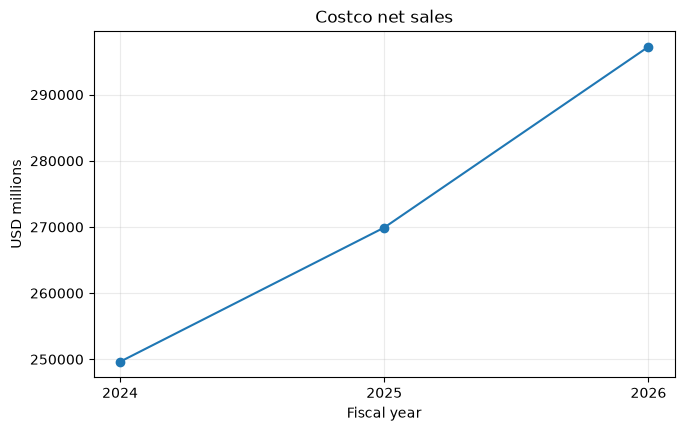

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(df["fiscal_year"].astype(str), df["net_sales_usd_m"], marker="o")
ax.set(title="Costco net sales", xlabel="Fiscal year", ylabel="USD millions")
ax.grid(alpha=0.25)
plt.show()

## 4 — Inventory and payables: where Supply Chain enters

2026 **Days Inventory Outstanding (DIO)** = 365 × average(2025, 2026 inventory) / 2026 merchandise costs. We also estimate **Days Payables Outstanding (DPO)** using merchandise costs as a **rough proxy** for purchases (actual supplier purchases would be preferable).

These are *aggregated company-level approximations*, not store-by-store measures. There is no 2024 balance-sheet amount in this small source extract, so a proper 2025 turnover calculation is unavailable here.

In [5]:
inventory_2025 = float(df.loc[df.fiscal_year == 2025, "inventory_usd_m"].iloc[0])
inventory_2026 = float(df.loc[df.fiscal_year == 2026, "inventory_usd_m"].iloc[0])
payable_2025 = float(df.loc[df.fiscal_year == 2025, "accounts_payable_usd_m"].iloc[0])
payable_2026 = float(df.loc[df.fiscal_year == 2026, "accounts_payable_usd_m"].iloc[0])
merchandise_cost_2026 = float(df.loc[df.fiscal_year == 2026, "merchandise_costs_usd_m"].iloc[0])

avg_inventory = (inventory_2025 + inventory_2026) / 2
avg_payables = (payable_2025 + payable_2026) / 2
DIO_2026 = 365 * avg_inventory / merchandise_cost_2026
DPO_2026_proxy = 365 * avg_payables / merchandise_cost_2026
print(f"2026 DIO: {DIO_2026:.2f} days")
print(f"2026 DPO (COGS proxy, not true purchases): {DPO_2026_proxy:.2f} days")

2026 DIO: 25.85 days
2026 DPO (COGS proxy, not true purchases): 29.26 days


## 5 — Save your first analysis file

In [6]:
out = project / "data" / "costco_first_analysis.csv"
df.to_csv(out, index=False)
print("Created:", out)

Created: C:\Users\wange\OneDrive\College\Costco-Financial-Analytics\data\costco_first_analysis.csv


## 6 — OPTIONAL: download Costco's entire SEC Company Facts JSON

This is **not required** for the exercises above. It requires an internet connection; the SEC might reject generic or misidentified automated requests. Put your **real contact email** in the User-Agent string and run this cell once. The SEC's Company Facts API includes tagged values across years and filings; later we'll clean those into a fuller time series. An SEC filing contains repeated historical facts, so `fiscal_year` and filing year are **not** always the same observation period; inspect `start`, `end`, `filed` and `form` before calculations.

SEC source: https://www.sec.gov/search-filings/edgar-application-programming-interfaces

In [7]:
import requests

from getpass import getpass
YOUR_EMAIL = getpass("Enter SEC contact email: ").strip()
if YOUR_EMAIL.startswith("REPLACE_"):
    print("Edit YOUR_EMAIL first; offline exercise already works.")
else:
    endpoint = "https://data.sec.gov/api/xbrl/companyfacts/CIK0000909832.json"
    response = requests.get(
        endpoint,
        headers={"User-Agent": f"Independent analytics learning {YOUR_EMAIL}"},
        timeout=40,
    )
    response.raise_for_status()
    costco_facts = response.json()
    raw_file = project / "data" / "costco_companyfacts_full.json"
    raw_file.write_text(response.text, encoding="utf-8")
    print("Saved live SEC JSON:", raw_file, "with", len(costco_facts.get("facts",{}).get("us-gaap",{})), "us-gaap concepts")

Enter SEC contact email:  ········


Saved live SEC JSON: C:\Users\wange\OneDrive\College\Costco-Financial-Analytics\data\costco_companyfacts_full.json with 476 us-gaap concepts


## 7 — OPTIONAL: search the financial tags (run after successful Section 6 download)

In [12]:
import json
raw_file = project / "data" / "costco_companyfacts_full.json"
if raw_file.exists():
    costco_facts = json.loads(raw_file.read_text(encoding="utf-8"))
    tag_list = []
    for taxonomy, concepts in costco_facts.get("facts", {}).items():
        for tag, entry in concepts.items():
            tag_list.append({"taxonomy": taxonomy, "tag": tag, "label": entry.get("label", "")})
    tags = pd.DataFrame(tag_list)
    display(tags[tags["tag"].str.contains("inventory|inventories|payable|revenue|sales|costof", case=False, regex=True)].head(70))
else:
    print("Download the SEC JSON in Section 6 first. The offline exercises are complete.")

,taxonomy,tag,label
2,us-gaap,AccountsPayableCurrent,"Accounts Payable, Current"
7,us-gaap,AccumulatedOtherComprehensiveIncomeLossAvailab...,"AOCI, Debt Securities, Available-for-sale, Adj..."
21,us-gaap,AvailableForSaleSecurities,Available-for-sale Securities
22,us-gaap,AvailableForSaleSecuritiesDebtMaturitiesAfterF...,"Debt Securities, Available-for-Sale, Amortized..."
23,us-gaap,AvailableForSaleSecuritiesDebtMaturitiesAfterF...,"Debt Securities, Available-for-Sale, Fair Valu..."
24,us-gaap,AvailableForSaleSecuritiesDebtMaturitiesAfterO...,"Debt Securities, Available-for-Sale, Amortized..."
25,us-gaap,AvailableForSaleSecuritiesDebtMaturitiesAfterO...,"Debt Securities, Available-for-Sale, Fair Valu..."
26,us-gaap,AvailableForSaleSecuritiesDebtMaturitiesAmorti...,"Available-for-sale Securities, Debt Maturities..."
27,us-gaap,AvailableForSaleSecuritiesDebtMaturitiesFairValue,"Available-for-sale Securities, Debt Maturities..."
28,us-gaap,AvailableForSaleSecuritiesDebtMaturitiesWithin...,"Debt Securities, Available-for-Sale, Amortized..."


# The first historical SEC time series

In [13]:
wanted = ["InventoryNet", "AccountsPayableCurrent"]

records = []

for tag in wanted:
    observations = costco_facts["facts"]["us-gaap"][tag]["units"]["USD"]

    for obs in observations:
        if obs.get("form") == "10-K" and "start" not in obs:
            records.append({
                "metric": tag,
                "date": obs["end"],
                "value_billions": obs["val"] / 1e9,
                "filed": obs["filed"]
            })

history = pd.DataFrame(records)

# Keep the latest-filed value for each metric and date.
history = (
    history.sort_values("filed")
    .drop_duplicates(["metric", "date"], keep="last")
)

history_table = history.pivot(
    index="date",
    columns="metric",
    values="value_billions"
).sort_index()

print(history_table.tail(12).round(2).to_string())


metric      AccountsPayableCurrent  InventoryNet
date                                            
2015-08-30                    9.01          8.91
2016-08-28                    7.61          8.97
2017-09-03                    9.61          9.83
2018-09-02                   11.24         11.04
2019-09-01                   11.68         11.40
2020-08-30                   14.17         12.24
2021-08-29                   16.28         14.22
2022-08-28                   17.85         17.91
2023-09-03                   17.48         16.65
2024-09-01                   19.42         18.65
2025-08-31                   19.78         18.12
2026-08-30                   22.59         19.32


# Session 2: Year-over-year change

In [15]:
growth = history_table.pct_change() * 100

print("Annual percentage changes:")
print(growth.round(2).to_string())


Annual percentage changes:
metric      AccountsPayableCurrent  InventoryNet
date                                            
2009-08-30                     NaN           NaN
2010-08-29                    9.12          4.31
2011-08-28                   10.04         17.74
2012-09-02                   11.60          6.90
2013-09-01                    7.79         11.25
2014-08-31                    7.86          7.12
2015-08-30                    6.12          5.35
2016-08-28                  -15.53          0.68
2017-09-03                   26.22          9.64
2018-09-02                   16.95         12.26
2019-09-01                    3.93          3.22
2020-08-30                   21.35          7.43
2021-08-29                   14.86         16.12
2022-08-28                    9.64         25.97
2023-09-03                   -2.05         -7.01
2024-09-01                   11.09         11.99
2025-08-31                    1.86         -2.85
2026-08-30                   14.19        

# Plot year-over-year growth

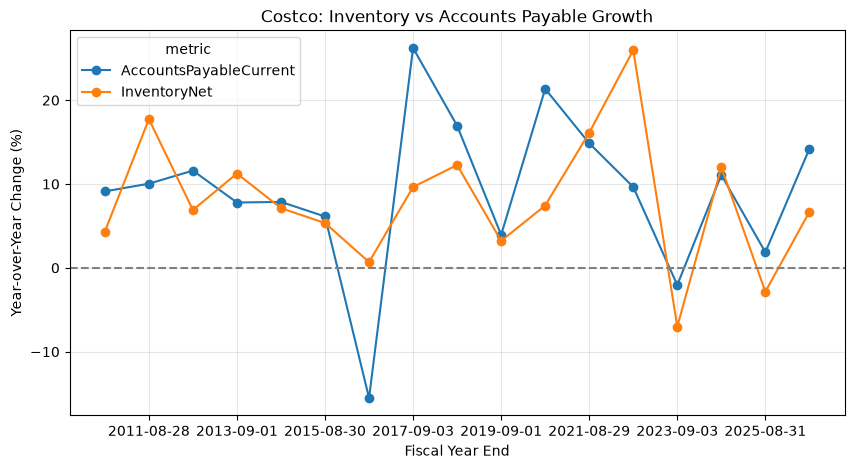

In [16]:
import matplotlib.pyplot as plt

ax = growth.plot(
    figsize=(10, 5),
    marker="o",
    title="Costco: Inventory vs Accounts Payable Growth"
)

ax.set_xlabel("Fiscal Year End")
ax.set_ylabel("Year-over-Year Change (%)")
ax.axhline(0, color="gray", linestyle="--")
ax.grid(alpha=0.3)

plt.show()


# Extract annual merchandise costs from SEC XBRL

In [17]:
observations = costco_facts["facts"]["us-gaap"][
    "CostOfGoodsAndServicesSold"
]["units"]["USD"]

cogs_rows = []

for obs in observations:
    if obs.get("form") != "10-K" or not obs.get("start"):
        continue

    days = (
        pd.Timestamp(obs["end"]) -
        pd.Timestamp(obs["start"])
    ).days + 1

    # Keep approximately full-year observations
    if 350 <= days <= 380:
        cogs_rows.append({
            "date": obs["end"],
            "filed": obs["filed"],
            "merchandise_costs_b": obs["val"] / 1e9
        })

cogs = (
    pd.DataFrame(cogs_rows)
    .sort_values("filed")
    .drop_duplicates("date", keep="last")
    .set_index("date")
    .sort_index()
)

print(cogs.tail(12).round(2).to_string())


                 filed  merchandise_costs_b
date                                       
2016-08-28  2018-10-26               102.90
2017-09-03  2019-10-11               111.88
2018-09-02  2020-10-07               123.15
2019-09-01  2021-10-06               132.89
2020-08-30  2022-10-05               144.94
2021-08-29  2023-10-11               170.68
2022-08-28  2024-10-09               199.38
2023-09-03  2025-10-08               212.59
2024-09-01  2026-10-07               222.36
2025-08-31  2026-10-07               239.89
2026-08-30  2026-10-07               264.28


# Combine historical balance sheets and merchandise costs

In [19]:
analysis = history_table.join(
    cogs[["merchandise_costs_b"]],
    how="left"
)

# Average two consecutive year-end balances
analysis["avg_inventory_b"] = (
    analysis["InventoryNet"] +
    analysis["InventoryNet"].shift(1)
) / 2

analysis["avg_payables_b"] = (
    analysis["AccountsPayableCurrent"] +
    analysis["AccountsPayableCurrent"].shift(1)
) / 2

# Working capital efficiency
analysis["DIO"] = (
    365 * analysis["avg_inventory_b"] /
    analysis["merchandise_costs_b"]
)

analysis["DPO_proxy"] = (
    365 * analysis["avg_payables_b"] /
    analysis["merchandise_costs_b"]
)

print(
    analysis[
        ["merchandise_costs_b", "DIO", "DPO_proxy"]
    ].tail(12).round(2).to_string()
)


            merchandise_costs_b    DIO  DPO_proxy
date                                             
2015-08-30                  NaN    NaN        NaN
2016-08-28               102.90  31.71      29.48
2017-09-03               111.88  30.67      28.09
2018-09-02               123.15  30.93      30.89
2019-09-01               132.89  30.81      31.47
2020-08-30               144.94  29.76      32.55
2021-08-29               170.68  28.29      32.56
2022-08-28               199.38  29.40      31.24
2023-09-03               212.59  29.67      30.33
2024-09-01               222.36  28.97      30.29
2025-08-31               239.89  27.97      29.83
2026-08-30               264.28  25.85      29.26


# Compare inventory days with supplier-payment days

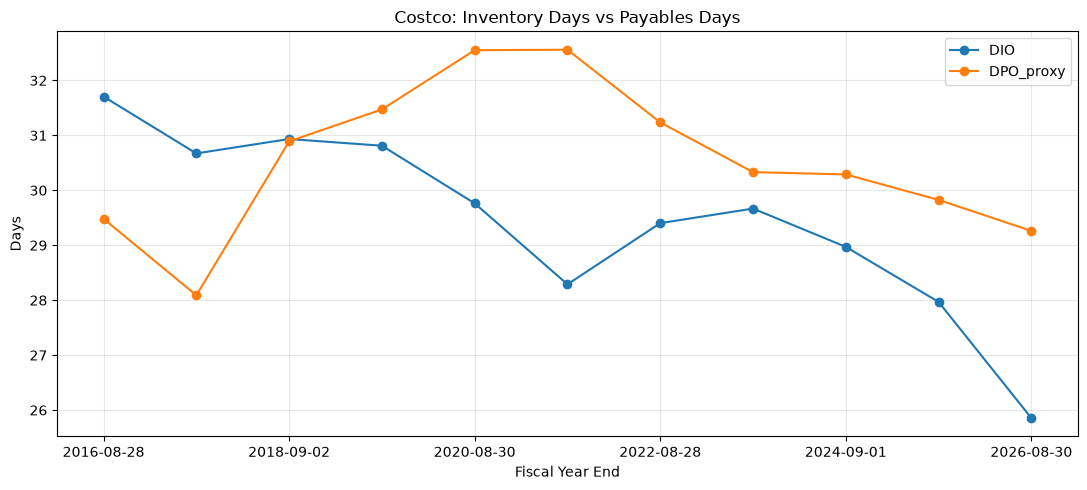

In [20]:
ax = analysis[["DIO", "DPO_proxy"]].dropna().plot(
    figsize=(11, 5),
    marker="o",
    title="Costco: Inventory Days vs Payables Days"
)

ax.set_xlabel("Fiscal Year End")
ax.set_ylabel("Days")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [23]:
analysis["DPO_minus_DIO"] = (
    analysis["DPO_proxy"] - analysis["DIO"]
)

print(
    analysis[["DPO_proxy", "DIO", "DPO_minus_DIO"]]
    .dropna()
    .round(2)
    .to_string()
)


            DPO_proxy    DIO  DPO_minus_DIO
date                                       
2016-08-28      29.48  31.71          -2.22
2017-09-03      28.09  30.67          -2.58
2018-09-02      30.89  30.93          -0.04
2019-09-01      31.47  30.81           0.66
2020-08-30      32.55  29.76           2.79
2021-08-29      32.56  28.29           4.27
2022-08-28      31.24  29.40           1.83
2023-09-03      30.33  29.67           0.66
2024-09-01      30.29  28.97           1.32
2025-08-31      29.83  27.97           1.86
2026-08-30      29.26  25.85           3.41
